# Nhận diện chữ số viết tay — Neural Network from scratch

**Tuân thủ đề:** Chỉ lấy dữ liệu bằng `sklearn.datasets.load_digits()`. Không dùng TensorFlow, Keras, PyTorch hoặc mô hình sklearn. Forward, backpropagation, Adam, chia dữ liệu và các chỉ số đều tự viết bằng NumPy. OpenCV chỉ xử lý ảnh/camera.

Notebook này chứa toàn bộ code huấn luyện, chạy từ trên xuống. File ZIP là gói để nộp; không cần Colab/Kaggle, không tải MNIST hoặc trọng số bên ngoài.

## 1. Chuẩn bị
Cài các gói trong `requirements.txt` rồi mở notebook bằng Jupyter. Chọn **Restart Kernel and Run All Cells**. Chạy trong thư mục vừa giải nén để trọng số được lưu cạnh app camera.

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
"""
Train neural network nhận diện chữ số viết tay hoàn toàn FROM SCRATCH bằng NumPy.

Yêu cầu bài tập được tuân thủ:
- Dataset duy nhất: sklearn.datasets.load_digits().
- KHÔNG dùng TensorFlow / Keras / PyTorch.
- KHÔNG dùng model, train_test_split, scaler, metric... của sklearn.
- Forward, backpropagation, Adam, chia train/validation/test và accuracy đều tự cài.

Data augmentation chỉ tạo biến thể từ chính load_digits (xoay/dịch/co giãn nhẹ),
không đưa thêm dataset bên ngoài. Mục đích là giúp model chịu được sai lệch khi
đưa chữ viết tay thật qua camera.
"""

from pathlib import Path
import math
import json
import cv2
import numpy as np
from sklearn.datasets import load_digits  # sklearn CHỈ dùng để lấy dataset

SEED = 42
EPOCHS = 55
BATCH_SIZE = 128
AUG_PER_SAMPLE = 7          # 1 ảnh gốc + 7 ảnh biến đổi
LEARNING_RATE_MAX = 2.5e-3
LEARNING_RATE_MIN = 2.0e-4
L2 = 2.0e-4
DROPOUT = 0.10
LABEL_SMOOTHING = 0.02
OUTPUT_WEIGHTS = Path.cwd() / "digit_nn_weights.npz"




## 2. Tách nét chữ và mô phỏng ảnh camera
Cùng một hàm tiền xử lý được dùng cho ảnh mô phỏng và camera thật. Tự xác định nền sáng/tối, loại component nhiễu/chạm biên, giữ nét chữ chính rồi thu về 8×8. Mô phỏng chỉ biến đổi ảnh gốc sklearn, không bổ sung bộ dữ liệu khác. Đây là một giả định về ảnh camera; chất lượng thực tế phải thử trên camera thật.

In [2]:
"""Tiền xử lý dùng chung; OpenCV chỉ xử lý ảnh, không học mô hình."""
import cv2
import numpy as np

def preprocess_roi(gray_roi, padding_factor=1.04):
    empty = (None, np.zeros((8, 8), np.uint8), None)
    if gray_roi is None or gray_roi.ndim != 2 or min(gray_roi.shape) < 8:
        return empty
    gray = np.clip(gray_roi, 0, 255).astype(np.uint8)
    if np.percentile(gray, 98) - np.percentile(gray, 2) < 12:
        return empty
    blur = cv2.GaussianBlur(gray, (3, 3), 0)
    border = np.concatenate((blur[0], blur[-1], blur[:, 0], blur[:, -1]))
    # Tự nhận nền trắng/nền tối bằng cường độ ở biên.
    ink = 255 - blur if np.median(border) > 127 else blur
    _, mask = cv2.threshold(ink, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    h, w = mask.shape
    n, labels, stats, centers = cv2.connectedComponentsWithStats(mask, 8)
    candidates = []
    for i in range(1, n):
        x, y, bw, bh, area = stats[i]
        if area < max(12, h*w*0.0015) or area > h*w*0.60:
            continue
        # Loại vùng chạm mép ROI: thường là bóng, viền giấy hoặc chữ bị cắt.
        if x <= 0 or y <= 0 or x+bw >= w or y+bh >= h:
            continue
        cx, cy = centers[i]
        score = area / (1 + 2*((cx/w-.5)**2 + (cy/h-.5)**2))
        candidates.append((score, i))
    if not candidates:
        return empty
    best = max(candidates)[1]
    x, y, bw, bh, area = stats[best]
    selected = (labels == best).astype(np.uint8)
    # Giữ quầng xám sát nét để resize chống răng cưa; loại nền/nhiễu bên ngoài.
    support = cv2.dilate(selected, np.ones((3,3), np.uint8))
    bg = float(np.median(ink[mask == 0])) if np.any(mask == 0) else 0.
    foreground = np.maximum(ink.astype(np.float32) - bg, 0) * support
    crop = foreground[y:y+bh, x:x+bw]
    side = max(bw, bh)
    size = max(side, int(np.ceil(side*padding_factor)))
    canvas = np.zeros((size, size), np.float32)
    oy, ox = (size-bh)//2, (size-bw)//2
    canvas[oy:oy+bh, ox:ox+bw] = crop
    small = cv2.resize(canvas, (8,8), interpolation=cv2.INTER_AREA)
    peak = float(small.max())
    if peak < 8:
        return empty
    small = np.clip(small/peak, 0, 1)
    return small.reshape(64), (small*255).astype(np.uint8), (x,y,x+bw-1,y+bh-1)

def render_camera_sample(img8, rng):
    """Mô phỏng giấy/ánh sáng từ một ảnh load_digits; không thêm dữ liệu ngoài."""
    up = cv2.resize(img8, (72,72), interpolation=cv2.INTER_CUBIC)
    matrix = cv2.getRotationMatrix2D((35.5,35.5), float(rng.uniform(-10,10)), float(rng.uniform(.82,1.0)))
    up = cv2.warpAffine(up, matrix, (72,72))
    canvas = np.zeros((112,112), np.float32)
    oy, ox = rng.integers(14,26,size=2)
    canvas[oy:oy+72,ox:ox+72] = np.clip(up,0,1)
    paper = float(rng.uniform(185,250)) + np.linspace(-12,12,112)[None,:]
    gray = paper - canvas*float(rng.uniform(100,180))
    gray += rng.normal(0,1.2,gray.shape)
    gray = np.clip(gray,0,255).astype(np.uint8)
    return 255-gray if rng.random()<.25 else gray


## 3. Chia dữ liệu trước khi tạo biến thể
Chia theo từng nhãn: khoảng 70% train, 15% validation, 15% test. Mỗi ảnh gốc và các biến thể chỉ thuộc một tập. Test không dùng chọn checkpoint. Mỗi ảnh train có một bản gốc và bảy biến thể.

In [3]:
def stratified_split(y, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    """Tự chia dữ liệu theo từng lớp, không dùng train_test_split của sklearn."""
    rng = np.random.default_rng(seed)
    train_idx, val_idx, test_idx = [], [], []
    for cls in range(10):
        idx = np.where(y == cls)[0].copy()
        rng.shuffle(idx)
        n = len(idx)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        train_idx.extend(idx[:n_train])
        val_idx.extend(idx[n_train:n_train + n_val])
        test_idx.extend(idx[n_train + n_val:])

    train_idx = np.asarray(train_idx, dtype=np.int64)
    val_idx = np.asarray(val_idx, dtype=np.int64)
    test_idx = np.asarray(test_idx, dtype=np.int64)
    rng.shuffle(train_idx)
    rng.shuffle(val_idx)
    rng.shuffle(test_idx)
    return train_idx, val_idx, test_idx


def augment_image(img8, rng):
    """Biến đổi nhẹ ảnh 8x8 từ load_digits để model bền hơn khi dùng camera."""
    up = cv2.resize(img8, (32, 32), interpolation=cv2.INTER_CUBIC)

    angle = float(rng.uniform(-14.0, 14.0))
    scale = float(rng.uniform(0.88, 1.12))
    tx = float(rng.uniform(-3.0, 3.0))
    ty = float(rng.uniform(-3.0, 3.0))

    M = cv2.getRotationMatrix2D((15.5, 15.5), angle, scale)
    M[:, 2] += (tx, ty)
    out = cv2.warpAffine(
        up, M, (32, 32), flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT, borderValue=0
    )

    r = rng.random()
    kernel = np.ones((2, 2), dtype=np.uint8)
    if r < 0.22:
        out = cv2.dilate(out, kernel, iterations=1)   # nét dày hơn
    elif r < 0.38:
        out = cv2.erode(out, kernel, iterations=1)    # nét mảnh hơn

    if rng.random() < 0.40:
        out = cv2.GaussianBlur(out, (3, 3), float(rng.uniform(0.2, 0.8)))

    out = cv2.resize(out, (8, 8), interpolation=cv2.INTER_AREA)
    gamma = float(rng.uniform(0.75, 1.30))
    out = np.clip(out, 0.0, 1.0) ** gamma
    out *= float(rng.uniform(0.85, 1.15))

    if rng.random() < 0.30:
        out += rng.normal(0.0, 0.025, out.shape)

    return np.clip(out, 0.0, 1.0).astype(np.float32)


def build_augmented_set(images, labels, indices, aug_per_sample, seed):
    rng = np.random.default_rng(seed)
    X_list, y_list = [], []
    for idx in indices:
        img = images[idx]
        X_list.append(img)
        y_list.append(labels[idx])
        for j in range(aug_per_sample):
            if j % 2 == 0:
                vector, _, _ = preprocess_roi(render_camera_sample(img, rng))
                transformed = vector.reshape(8,8) if vector is not None else augment_image(img, rng)
            else:
                transformed = augment_image(img, rng)
            X_list.append(transformed)
            y_list.append(labels[idx])
    X = np.asarray(X_list, dtype=np.float32).reshape(-1, 64)
    y = np.asarray(y_list, dtype=np.int64)
    return X, y




## 4. Mạng neural tự viết: 64 → 192 → 96 → 10
- 64 đầu vào là 64 pixel; 10 đầu ra tương ứng số 0–9.
- Lớp ẩn: $Z=AW+b$, $A=\max(0,Z)$ (ReLU). Softmax chuyển đầu ra thành phân phối xác suất.
- Cross-entropy với label smoothing giảm tự tin quá mức. Gradient đầu ra là $(P-Y)/N$.
- Backprop truyền gradient ngược qua các lớp. Adam dùng trung bình gradient và bình phương gradient để cập nhật trọng số.
- He initialization, dropout và L2 giúp huấn luyện ổn định, hạn chế học thuộc. Learning rate giảm theo cosine.

Xác suất softmax không phải cam kết rằng dự đoán camera đúng với tỷ lệ tương ứng.

In [4]:
def relu(z):
    return np.maximum(z, 0.0)


def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)


class NeuralNetwork:
    """MLP 64 -> 192 -> 96 -> 10, forward/backprop tự cài bằng NumPy."""

    def __init__(self, sizes=(64, 192, 96, 10), seed=7, l2=L2, dropout=DROPOUT):
        rng = np.random.default_rng(seed)
        self.sizes = tuple(sizes)
        self.l2 = float(l2)
        self.dropout = float(dropout)
        self.W, self.b = [], []

        # He initialization cho ReLU
        for fan_in, fan_out in zip(self.sizes[:-1], self.sizes[1:]):
            W = rng.standard_normal((fan_in, fan_out)).astype(np.float32)
            W *= np.sqrt(2.0 / fan_in)
            self.W.append(W)
            self.b.append(np.zeros((1, fan_out), dtype=np.float32))

        # trạng thái Adam
        self.mW = [np.zeros_like(w) for w in self.W]
        self.vW = [np.zeros_like(w) for w in self.W]
        self.mb = [np.zeros_like(b) for b in self.b]
        self.vb = [np.zeros_like(b) for b in self.b]
        self.t = 0

    def forward(self, X, training=False, rng=None):
        A = X
        activations = [A]
        pre_activations = []
        dropout_masks = []

        for layer in range(len(self.W)):
            Z = A @ self.W[layer] + self.b[layer]
            pre_activations.append(Z)

            if layer == len(self.W) - 1:
                A = softmax(Z)
                dropout_masks.append(None)
            else:
                A = relu(Z)
                mask = None
                if training and self.dropout > 0:
                    mask = (rng.random(A.shape) >= self.dropout).astype(np.float32)
                    mask /= (1.0 - self.dropout)
                    A *= mask
                dropout_masks.append(mask)

            activations.append(A)

        cache = (activations, pre_activations, dropout_masks)
        return A, cache

    def train_batch(self, X, y, lr, rng, label_smoothing=LABEL_SMOOTHING):
        probs, cache = self.forward(X, training=True, rng=rng)
        activations, pre_activations, dropout_masks = cache

        n = len(X)
        num_classes = probs.shape[1]
        target = np.full_like(probs, label_smoothing / (num_classes - 1))
        target[np.arange(n), y] = 1.0 - label_smoothing

        dZ = (probs - target) / n
        gW = [None] * len(self.W)
        gb = [None] * len(self.b)

        for layer in range(len(self.W) - 1, -1, -1):
            A_prev = activations[layer]
            gW[layer] = A_prev.T @ dZ + self.l2 * self.W[layer]
            gb[layer] = np.sum(dZ, axis=0, keepdims=True)

            if layer > 0:
                dA = dZ @ self.W[layer].T
                if dropout_masks[layer - 1] is not None:
                    dA *= dropout_masks[layer - 1]
                dZ = dA * (pre_activations[layer - 1] > 0.0)

        # Adam optimizer tự cài
        self.t += 1
        beta1, beta2, eps = 0.9, 0.999, 1e-8
        for i in range(len(self.W)):
            self.mW[i] = beta1 * self.mW[i] + (1 - beta1) * gW[i]
            self.vW[i] = beta2 * self.vW[i] + (1 - beta2) * (gW[i] ** 2)
            self.mb[i] = beta1 * self.mb[i] + (1 - beta1) * gb[i]
            self.vb[i] = beta2 * self.vb[i] + (1 - beta2) * (gb[i] ** 2)

            mW_hat = self.mW[i] / (1 - beta1 ** self.t)
            vW_hat = self.vW[i] / (1 - beta2 ** self.t)
            mb_hat = self.mb[i] / (1 - beta1 ** self.t)
            vb_hat = self.vb[i] / (1 - beta2 ** self.t)

            self.W[i] -= lr * mW_hat / (np.sqrt(vW_hat) + eps)
            self.b[i] -= lr * mb_hat / (np.sqrt(vb_hat) + eps)

    def predict_proba(self, X):
        probs, _ = self.forward(X, training=False)
        return probs

    def accuracy(self, X, y):
        pred = np.argmax(self.predict_proba(X), axis=1)
        return float(np.mean(pred == y))

    def snapshot(self):
        return [w.copy() for w in self.W], [b.copy() for b in self.b]

    def restore(self, snapshot):
        Ws, bs = snapshot
        self.W = [w.copy() for w in Ws]
        self.b = [b.copy() for b in bs]

    def save(self, path):
        np.savez(
            path,
            W1=self.W[0], b1=self.b[0],
            W2=self.W[1], b2=self.b[1],
            W3=self.W[2], b3=self.b[2],
            architecture=np.asarray(self.sizes, dtype=np.int32),
        )




## 5. Huấn luyện và chọn checkpoint
55 epoch; chọn checkpoint theo 65% accuracy validation sạch + 35% accuracy validation gồm ảnh biến đổi. Chỉ sau đó đánh giá test một lần. Tập test biến đổi gồm cả ảnh gốc và hai biến thể mỗi ảnh; đây không phải test camera thật.

In [5]:
def main():
    print("Đang tải dataset sklearn.datasets.load_digits()...")
    digits = load_digits()
    images = (digits.images.astype(np.float32) / 16.0)
    labels = digits.target.astype(np.int64)

    train_idx, val_idx, test_idx = stratified_split(labels)
    print(f"Train gốc: {len(train_idx)} | Validation: {len(val_idx)} | Test: {len(test_idx)}")

    print("Đang tạo augmentation chỉ từ dữ liệu load_digits...")
    X_train, y_train = build_augmented_set(
        images, labels, train_idx, AUG_PER_SAMPLE, seed=1234
    )
    X_val = images[val_idx].reshape(-1, 64)
    y_val = labels[val_idx]
    X_test = images[test_idx].reshape(-1, 64)
    y_test = labels[test_idx]

    # validation biến đổi để chọn model không chỉ giỏi ảnh sạch
    X_val_aug, y_val_aug = build_augmented_set(
        images, labels, val_idx, aug_per_sample=2, seed=4321
    )

    print(f"Số mẫu train sau augmentation: {len(X_train)}")
    model = NeuralNetwork()
    rng = np.random.default_rng(999)

    best_score = -1.0
    best_snapshot = None
    best_epoch = 0

    history = []
    for epoch in range(1, EPOCHS + 1):
        order = rng.permutation(len(X_train))
        progress = (epoch - 1) / max(1, EPOCHS - 1)
        lr = LEARNING_RATE_MIN + (LEARNING_RATE_MAX - LEARNING_RATE_MIN) * 0.5 * (
            1.0 + math.cos(math.pi * progress)
        )

        for start in range(0, len(order), BATCH_SIZE):
            idx = order[start:start + BATCH_SIZE]
            model.train_batch(X_train[idx], y_train[idx], lr, rng)

        clean_val = model.accuracy(X_val, y_val)
        aug_val = model.accuracy(X_val_aug, y_val_aug)
        score = 0.65 * clean_val + 0.35 * aug_val

        history.append({"epoch": epoch, "val_clean": clean_val, "val_augmented": aug_val})
        if score > best_score:
            best_score = score
            best_snapshot = model.snapshot()
            best_epoch = epoch

        if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
            print(
                f"Epoch {epoch:02d}/{EPOCHS} | lr={lr:.6f} | "
                f"val sạch={clean_val*100:.2f}% | val biến đổi={aug_val*100:.2f}%"
            )

    model.restore(best_snapshot)
    test_acc = model.accuracy(X_test, y_test)
    aug_val_acc = model.accuracy(X_val_aug, y_val_aug)

    # Test chỉ đánh giá sau khi chọn checkpoint bằng validation.
    X_test_aug, y_test_aug = build_augmented_set(images, labels, test_idx, 2, seed=9876)
    pred = model.predict_proba(X_test).argmax(axis=1)
    confusion = np.zeros((10,10), dtype=int)
    np.add.at(confusion, (y_test, pred), 1)
    metrics = {"seed": SEED, "train_original": len(train_idx), "validation_original": len(val_idx),
               "test_original": len(test_idx), "best_epoch": best_epoch,
               "test_clean_accuracy": test_acc, "test_augmented_accuracy": model.accuracy(X_test_aug,y_test_aug),
               "confusion_matrix": confusion.tolist(), "history": history,
               "note": "Synthetic transformations of load_digits; not a real camera accuracy measurement."}
    OUTPUT_WEIGHTS.with_name("evaluation.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    model.save(OUTPUT_WEIGHTS)
    print("\nHoàn tất.")
    print(f"Best epoch: {best_epoch}")
    print(f"Validation biến đổi: {aug_val_acc*100:.2f}%")
    print(f"Test sạch (hold-out): {test_acc*100:.2f}%")
    print(f"Đã lưu trọng số: {OUTPUT_WEIGHTS}")
    print(f"Test gồm ảnh biến đổi: {metrics['test_augmented_accuracy']*100:.2f}%")
    return model, metrics



In [6]:
model, metrics = main()

Đang tải dataset sklearn.datasets.load_digits()...
Train gốc: 1252 | Validation: 266 | Test: 279
Đang tạo augmentation chỉ từ dữ liệu load_digits...
Số mẫu train sau augmentation: 10016
Epoch 01/55 | lr=0.002500 | val sạch=93.98% | val biến đổi=89.22%
Epoch 05/55 | lr=0.002469 | val sạch=97.74% | val biến đổi=95.74%
Epoch 10/55 | lr=0.002346 | val sạch=98.87% | val biến đổi=97.37%
Epoch 15/55 | lr=0.002139 | val sạch=99.62% | val biến đổi=98.12%
Epoch 20/55 | lr=0.001866 | val sạch=99.25% | val biến đổi=97.49%
Epoch 25/55 | lr=0.001550 | val sạch=99.62% | val biến đổi=98.37%
Epoch 30/55 | lr=0.001216 | val sạch=99.62% | val biến đổi=98.37%
Epoch 35/55 | lr=0.000895 | val sạch=99.62% | val biến đổi=98.37%
Epoch 40/55 | lr=0.000611 | val sạch=99.62% | val biến đổi=98.37%
Epoch 45/55 | lr=0.000389 | val sạch=99.62% | val biến đổi=98.50%
Epoch 50/55 | lr=0.000248 | val sạch=99.62% | val biến đổi=98.37%
Epoch 55/55 | lr=0.000200 | val sạch=99.62% | val biến đổi=98.37%

Hoàn tất.
Best epoch:

## 6. Kết quả thực nghiệm và lỗi theo từng chữ số

Số 0: 28/28 đúng
Số 1: 28/28 đúng
Số 2: 28/28 đúng
Số 3: 28/28 đúng
Số 4: 28/28 đúng
Số 5: 28/28 đúng
Số 6: 28/28 đúng
Số 7: 28/28 đúng
Số 8: 25/27 đúng
Số 9: 27/28 đúng


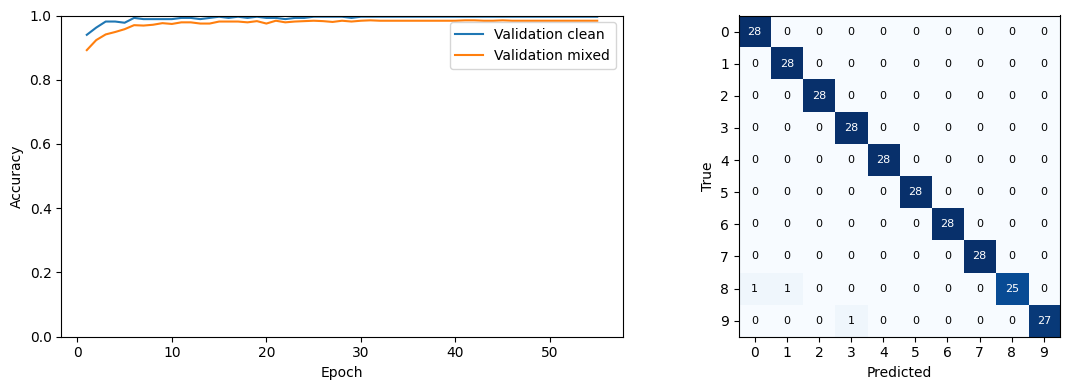

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
h = metrics['history']
ax[0].plot([r['epoch'] for r in h], [r['val_clean'] for r in h], label='Validation clean')
ax[0].plot([r['epoch'] for r in h], [r['val_augmented'] for r in h], label='Validation mixed')
ax[0].set(xlabel='Epoch', ylabel='Accuracy', ylim=(0,1))
ax[0].legend()
cm = np.array(metrics['confusion_matrix'])
ax[1].imshow(cm, cmap='Blues')
ax[1].set(xlabel='Predicted', ylabel='True', xticks=range(10), yticks=range(10))
for i in range(10):
    for j in range(10):
        ax[1].text(j,i,str(cm[i,j]),ha='center',va='center', color='white' if cm[i,j]>cm.max()/2 else 'black',fontsize=8)
plt.tight_layout()
plt.show()
for digit in range(10):
    print(f'Số {digit}: {cm[digit,digit]}/{cm[digit].sum()} đúng')

## 7. Dùng camera trên máy tính
Trong Terminal tại thư mục giải nén, chạy:
```
python camera_digit_recognizer.py --source 0
```
Đổi `0` thành `1` hoặc `2` nếu dùng camera khác. Đưa **một chữ số 0–9 mỗi lần** vào giữa khung, nét liền rõ, không chạm mép. Cửa sổ 8×8 cho thấy đúng ảnh đầu vào của mô hình. Nhấn `q` để thoát. Camera chạy riêng để Run All không bị chặn bởi vòng lặp video.

## 8. Giới hạn
`load_digits` có 1.797 ảnh 8×8 nên khác nhiều ảnh chụp thực tế. Không thể suy ra độ chính xác camera từ accuracy test sklearn. Chưa kiểm thử webcam vật lý trong môi trường tạo file. Không xử lý chuỗi nhiều chữ số hay chữ cái; component nét bị đứt có thể bị bỏ. Nếu ảnh 8×8 thiếu nét, hãy chỉnh khoảng cách, ánh sáng và vị trí giấy.